In [1]:
%pip install statsmodels folium

Note: you may need to restart the kernel to use updated packages.


# Phase 6a: Statistics, Price Elasticity, Stationarity and Geospatial Analysis

**Project:** FMCG Global Demand Planning Capstone
**Inputs:** `data/fmcg_clean.csv`, `data/abc_xyz_segments.csv`
**Outputs:** tables and figures in `reports/` (used for the README and presentation)

This notebook covers the parts of the course brief that Phases 1-5 did not:

| Brief requirement | Section |
|---|---|
| Mean, median, std and **CV by region** | 2 |
| **Correlation matrix** (price, promotion, volume) | 3 |
| **Price elasticity** for A-products | 4 |
| **Mann-Whitney U** test for promotional lift | 5 |
| **ADF stationarity test** | 6 |
| **Regional ABC comparison** | 7 |
| **Geospatial heat maps** and "logistics deserts" | 8 |
| Lead time variability vs stock-outs (store and city level) | 8.3 |

## 1. Setup and load data

In [2]:
# Run once; harmless if already installed.
%pip install statsmodels folium

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)
os.makedirs("../reports/figures", exist_ok=True)

def savefig(name):
    plt.savefig(f"../reports/figures/{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv("../data/fmcg_clean.csv", parse_dates=["date"])
df["series_id"] = df["store_id"] + "_" + df["sku_id"]
df["net_price"] = df["list_price"] * (1 - df["discount_pct"])   # price the shopper actually pays

seg = pd.read_csv("../data/abc_xyz_segments.csv").set_index("series_id")

# Version without stock-out days: sales on those days are capped by missing stock,
# so they do not show how shoppers respond to price or promotion.
dfa = df[df["stock_out_flag"] == 0].copy()

print("Rows:", f"{len(df):,}", "| Series:", df["series_id"].nunique(),
      "| Countries:", df["country"].nunique(), "| Cities:", df["city"].nunique(),
      "| Stores:", df["store_id"].nunique(), "| SKUs:", df["sku_id"].nunique(),
      "| Channels:", sorted(df["channel"].unique()))

Rows: 1,100,000 | Series: 1005 | Countries: 7 | Cities: 9 | Stores: 13 | SKUs: 102 | Channels: ['Convenience', 'E-commerce', 'Hypermarket', 'Supermarket']


## 2. Statistical baseline and demand volatility by region
Mean, median and standard deviation of daily units overall, then the **coefficient of variation (CV = std / mean)** of **weekly regional demand**. A higher CV means that region's demand swings more over time relative to its size. We drop the first and last (partial) weeks so they do not distort the result.

We also show the average CV of the individual store-SKU series in each region (from Phase 2), which measures how erratic a typical series is.

In [4]:
overall = df["units_sold"].agg(["mean", "median", "std"])
print("Daily units per store-SKU row:")
print(overall.round(2).to_string(), "\nCV:", round(overall["std"] / overall["mean"], 3))

weekly = (df.groupby(["country", "city", pd.Grouper(key="date", freq="W")])["units_sold"]
            .sum().reset_index())
weekly = weekly[(weekly["date"] > weekly["date"].min()) & (weekly["date"] < weekly["date"].max())]

def region_table(level):
    tot = weekly.groupby([level, "date"])["units_sold"].sum().reset_index()
    t = tot.groupby(level)["units_sold"].agg(mean="mean", median="median", std="std")
    t["CV"] = t["std"] / t["mean"]
    return t

by_country = region_table("country").sort_values("CV", ascending=False)
print("\nWeekly demand by country (sorted by CV):")
print(by_country.round(3).to_string())

by_city = region_table("city").sort_values("CV", ascending=False)
print("\nHighest-CV cities:")
print(by_city.head(8).round(3).to_string())
print("\nLowest-CV cities:")
print(by_city.tail(5).round(3).to_string())

Daily units per store-SKU row:
mean     59.200
median   49.000
std      45.010 
CV: 0.76

Weekly demand by country (sorted by CV):
                   mean      median       std    CV
country                                            
Netherlands  11,056.071  10,918.000   694.689 0.063
France       38,423.252  37,759.000 2,126.858 0.055
Austria      36,679.258  35,923.000 2,030.100 0.055
Poland       37,445.735  37,096.000 1,970.055 0.053
Italy       123,719.103 120,999.000 6,420.201 0.052
Germany      74,988.703  73,635.000 3,856.196 0.051
Spain        93,712.323  92,221.000 4,768.611 0.051

Highest-CV cities:
                mean     median       std    CV
city                                           
Amsterdam 11,056.071 10,918.000   694.689 0.063
Rome      65,409.716 64,162.000 3,644.914 0.056
Paris     38,423.252 37,759.000 2,126.858 0.055
Vienna    36,679.258 35,923.000 2,030.100 0.055
Madrid    33,497.877 32,862.000 1,835.714 0.055
Warsaw    37,445.735 37,096.000 1,970.055 0.0

Average weekly CV of individual series, by country:
             mean   min   max  count
country                             
Austria     0.186 0.119 0.293     80
France      0.190 0.122 0.300     80
Germany     0.187 0.118 0.301    160
Italy       0.187 0.118 0.320    320
Netherlands 0.197 0.115 0.315     45
Poland      0.188 0.116 0.306     80
Spain       0.186 0.118 0.316    240


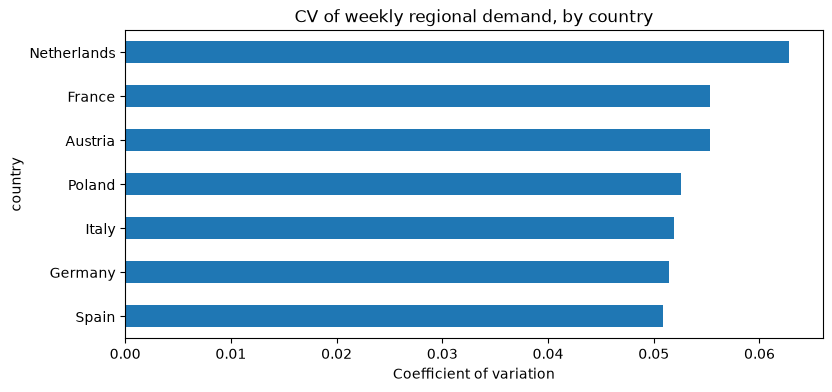

In [5]:
attrs = df.drop_duplicates("series_id").set_index("series_id")[["country", "city", "channel", "category"]]
series_cv = seg[["cv"]].join(attrs)
print("Average weekly CV of individual series, by country:")
print(series_cv.groupby("country")["cv"].agg(["mean", "min", "max", "count"]).round(3).to_string())

by_country["CV"].sort_values().plot(kind="barh", title="CV of weekly regional demand, by country")
plt.xlabel("Coefficient of variation")
savefig("cv_by_country")
plt.show()

## 3. Correlation matrix: price, promotion and volume
We correlate units sold with list price, net price (after discount), discount depth and the promo flag.

Two versions matter:
- **Pooled:** all rows together. This mixes differences *between* products (a cheap SKU may simply sell more) with real price response.
- **Within-series:** each variable minus that series' own average. This asks "when this product is priced or promoted differently from usual, does its volume change?", which is much closer to the elasticity question.

Pooled correlation:
              units_sold  list_price  net_price  discount_pct  promo_flag
units_sold         1.000      -0.085     -0.110         0.301       0.304
list_price        -0.085       1.000      0.995        -0.043      -0.048
net_price         -0.110       0.995      1.000        -0.134      -0.132
discount_pct       0.301      -0.043     -0.134         1.000       0.925
promo_flag         0.304      -0.048     -0.132         0.925       1.000

Within-series correlation:
              units_sold  list_price  net_price  discount_pct  promo_flag
units_sold         1.000      -0.000     -0.364         0.437       0.441
list_price        -0.000       1.000      0.000        -0.000       0.000
net_price         -0.364       0.000      1.000        -0.881      -0.805
discount_pct       0.437      -0.000     -0.881         1.000       0.915
promo_flag         0.441       0.000     -0.805         0.915       1.000


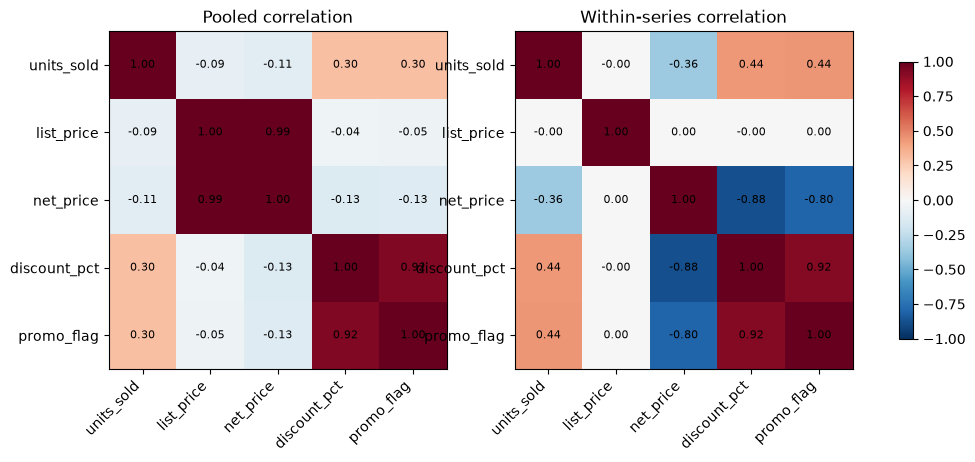


How much does list price vary within a series?
Series whose list price ever changes: 0 of 1005


In [6]:
cols = ["units_sold", "list_price", "net_price", "discount_pct", "promo_flag"]
pooled = dfa[cols].corr()
within = (dfa[cols] - dfa.groupby("series_id")[cols].transform("mean")).corr()

print("Pooled correlation:")
print(pooled.round(3).to_string())
print("\nWithin-series correlation:")
print(within.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, mat, title in zip(axes, [pooled, within], ["Pooled", "Within-series"]):
    im = ax.imshow(mat.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{title} correlation")
plt.colorbar(im, ax=axes, shrink=0.8)
savefig("correlation_matrix")
plt.show()

print("\nHow much does list price vary within a series?")
lp = dfa.groupby("series_id")["list_price"].agg(["min", "max", "std"])
print("Series whose list price ever changes:", (lp["std"] > 0).sum(), "of", len(lp))

## 4. Price elasticity of A-products
**Price elasticity** = % change in volume for a 1% change in price. An elasticity of -2 means a 1% price cut raises volume by about 2%. Values below -1 are "elastic" (volume responds more than proportionally).

**Method:** a log-log regression `log(units) = elasticity x log(price) + controls`, with a separate baseline for each series (series fixed effects, done by subtracting each series' own mean). Controls are weekend, holiday and month. Standard errors are clustered by series, because days within a series are not independent. Stock-out days and zero-sales rows are excluded.

**A-products** are the series in ABC class A from Phase 2.

Two specifications:
1. **Net price:** one elasticity for the price the shopper pays (list price after discount). It includes everything that comes with a promotion.
2. **Split:** separate effects for the **discount** and for the **list price**, if list price varies within series (checked in section 3).

If list price never changes within a series (check the end of section 3), all price variation comes from discounts, so the first two rows of the results will be identical and the list-price row will be absent. That is expected, not an error.

In [7]:
def within_ols(d, y, xcols):
    """Fixed-effects regression: subtract each series' mean, run OLS, cluster standard errors by series."""
    g = d["series_id"].values
    X = d[xcols].astype(float)
    Xd = (X - X.groupby(g).transform("mean")).values
    yd = (d[y] - d.groupby("series_id")[y].transform("mean")).values
    XtX_inv = np.linalg.pinv(Xd.T @ Xd)
    beta = XtX_inv @ (Xd.T @ yd)
    resid = yd - Xd @ beta
    scores = pd.DataFrame(Xd * resid[:, None]).groupby(g).sum().values   # per-series sums of x*e
    G = scores.shape[0]
    V = XtX_inv @ (scores.T @ scores) @ XtX_inv * G / (G - 1)
    se = np.sqrt(np.diag(V))
    return pd.DataFrame({"coef": beta, "se": se, "t": beta / se}, index=xcols)

A_ids = seg.index[seg["abc_class"] == "A"]
dA = dfa[dfa["series_id"].isin(A_ids) & (dfa["units_sold"] > 0)].copy()
dA["log_units"] = np.log(dA["units_sold"])
dA["log_net"]   = np.log(dA["net_price"])
dA["log_list"]  = np.log(dA["list_price"])
dA["log_disc"]  = np.log(1 - dA["discount_pct"])
print("A-product series:", dA["series_id"].nunique(), "| rows:", f"{len(dA):,}")

def controls(d):
    months = pd.get_dummies(d["month"], prefix="m", drop_first=True).astype(float)
    return pd.concat([d, months], axis=1), list(months.columns)

def elasticity(d, label):
    d, mcols = controls(d)
    base = ["is_weekend", "is_holiday"] + mcols
    out = []
    r1 = within_ols(d, "log_units", ["log_net"] + base).loc["log_net"]
    out.append({"group": label, "spec": "net price", "elasticity": r1["coef"], "se": r1["se"]})
    r2 = within_ols(d, "log_units", ["log_disc"] + base).loc["log_disc"]
    out.append({"group": label, "spec": "discount (promo price)", "elasticity": r2["coef"], "se": r2["se"]})
    if d.groupby("series_id")["log_list"].std().fillna(0).max() > 1e-9:
        r3 = within_ols(d, "log_units", ["log_list", "log_disc"] + base).loc["log_list"]
        out.append({"group": label, "spec": "list price (with discount controlled)",
                    "elasticity": r3["coef"], "se": r3["se"]})
    return out

rows = elasticity(dA, "All A-products")
for cat, part in dA.groupby("category"):
    rows += elasticity(part, cat)

elas = pd.DataFrame(rows)
elas["ci95_low"] = elas["elasticity"] - 1.96 * elas["se"]
elas["ci95_high"] = elas["elasticity"] + 1.96 * elas["se"]
print(elas.round(2).to_string(index=False))
elas.to_csv("../reports/price_elasticity.csv", index=False)

A-product series: 480 | rows: 509,681
         group                   spec  elasticity    se  ci95_low  ci95_high
All A-products              net price      -2.540 0.010    -2.560     -2.520
All A-products discount (promo price)      -2.540 0.010    -2.560     -2.520
     Beverages              net price      -2.560 0.020    -2.590     -2.530
     Beverages discount (promo price)      -2.560 0.020    -2.590     -2.530
         Dairy              net price      -2.630 0.030    -2.690     -2.570
         Dairy discount (promo price)      -2.630 0.030    -2.690     -2.570
     Home Care              net price      -2.510 0.020    -2.550     -2.480
     Home Care discount (promo price)      -2.510 0.020    -2.550     -2.480
 Personal Care              net price      -2.630 0.030    -2.690     -2.570
 Personal Care discount (promo price)      -2.630 0.030    -2.690     -2.570
        Snacks              net price      -2.550 0.020    -2.580     -2.520
        Snacks discount (promo price) 

### 4.1 Elasticity by discount depth (arc elasticity)
A single constant elasticity may not fit, because in Phase 3 lift grew roughly *linearly* with discount depth. We therefore compute, for each depth, the elasticity implied by moving from the non-promo baseline to that discount:

**elasticity = ln(promo units / baseline units) / ln(1 - discount)**

using each series' own promo and non-promo averages, then averaging across A-series.

          series  lift_%  arc_elasticity
discount                                
0.100        177  67.790          -4.900
0.150        177  79.520          -3.590
0.200        177  88.160          -2.830
0.300        177 108.970          -2.060


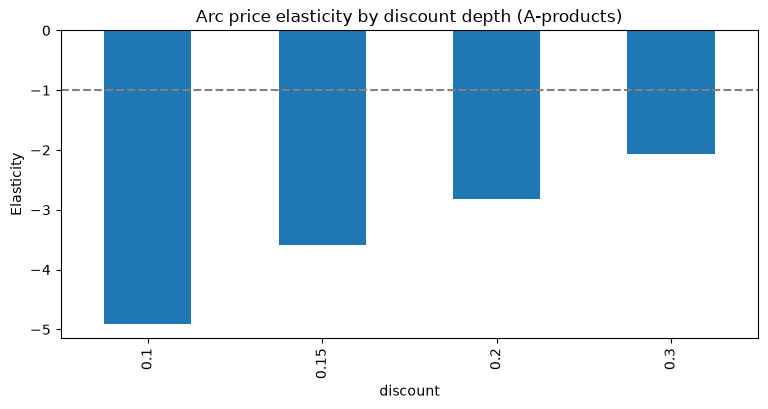

In [8]:
base = dA[dA["promo_flag"] == 0].groupby("series_id")["units_sold"].mean()
pr = dA[dA["promo_flag"] == 1].groupby(["series_id", "discount_pct"])["units_sold"].mean().unstack()
ratio = pr.div(base, axis=0)

arc = pd.DataFrame({
    "series": ratio.count(),
    "lift_%": (ratio.mean() - 1) * 100,
    "arc_elasticity": pd.Series({d: (np.log(ratio[d]) / np.log(1 - d)).mean() for d in ratio.columns}),
})
arc.index.name = "discount"
print(arc.round(2).to_string())

arc["arc_elasticity"].plot(kind="bar", title="Arc price elasticity by discount depth (A-products)")
plt.ylabel("Elasticity")
plt.axhline(-1, color="grey", linestyle="--")
savefig("arc_elasticity")
plt.show()
arc.to_csv("../reports/arc_elasticity_by_discount.csv")

## 5. Promotional lift: Mann-Whitney U test
The brief asks for a **t-test or Mann-Whitney U** comparing promo days with non-promo days. In Phase 3 we used paired tests across series. Here we run the row-level version.

**The pitfall:** comparing raw units mixes big and small series, so the result mostly reflects *which series get promoted*. We therefore also test **relative units** (each row divided by its own series' non-promo average), which removes volume differences. Only series that are promoted at some point are used.

- **H0:** promo and non-promo days have the same distribution of units.
- **H1:** promo days have higher units (one-sided).
- **Effect size:** the Mann-Whitney statistic gives the probability that a random promo day beats a random non-promo day (0.5 = no effect, 1.0 = always higher). With about a million rows the p-value will be tiny, so the effect size is what matters.

In [9]:
ever = dfa.groupby("series_id")["promo_flag"].max()
dfp = dfa[dfa["series_id"].map(ever) == 1].copy()

base_mean = dfp[dfp["promo_flag"] == 0].groupby("series_id")["units_sold"].mean()
dfp["rel_units"] = dfp["units_sold"] / dfp["series_id"].map(base_mean)

def mw(col, label):
    a = dfp.loc[dfp["promo_flag"] == 1, col]
    b = dfp.loc[dfp["promo_flag"] == 0, col]
    u, p = st.mannwhitneyu(a, b, alternative="greater", method="asymptotic")
    auc = u / (len(a) * len(b))
    t, pt = st.ttest_ind(a, b, equal_var=False, alternative="greater")
    return {"measure": label, "promo_n": len(a), "nonpromo_n": len(b),
            "promo_median": a.median(), "nonpromo_median": b.median(),
            "promo_mean": a.mean(), "nonpromo_mean": b.mean(),
            "MWU_p": p, "P(promo > nonpromo)": auc, "rank_biserial_r": 2 * auc - 1,
            "Welch_t": t, "Welch_p": pt}

mwu = pd.DataFrame([mw("units_sold", "raw units"), mw("rel_units", "relative units (own baseline = 1)")]).set_index("measure")
print(mwu.T.to_string())
mwu.to_csv("../reports/mann_whitney_promo.csv")

measure               raw units  relative units (own baseline = 1)
promo_n              85,544.000                         85,544.000
nonpromo_n          342,332.000                        342,332.000
promo_median             92.000                              1.813
nonpromo_median          49.000                              0.978
promo_mean              106.893                              1.866
nonpromo_mean            57.393                              1.000
MWU_p                     0.000                              0.000
P(promo > nonpromo)       0.720                              0.891
rank_biserial_r           0.440                              0.782
Welch_t                 190.830                            375.687
Welch_p                   0.000                              0.000


## 6. Stationarity: Augmented Dickey-Fuller (ADF) test
A series is **stationary** if its mean and variance do not drift over time. Many classical models need this, and differencing is the usual fix when it fails.

- **H0 (ADF):** the series has a unit root (non-stationary).
- **H1:** the series is stationary. A p-value below 0.05 rejects H0.

We test (a) total daily demand, (b) a random sample of 200 store-SKU series, and add the **KPSS** test as a cross-check (its null is the *opposite*: KPSS H0 = stationary, so we want ADF to reject and KPSS not to reject).

ADF cannot see a repeating weekly or yearly *pattern*; it detects trends and random-walk behaviour. Seasonality is handled separately (calendar features), so passing ADF does not mean "no seasonality".

In [10]:
from statsmodels.tsa.stattools import adfuller, kpss

daily_total = df.groupby("date")["units_sold"].sum()
adf = adfuller(daily_total, autolag="AIC")
print("ADF on total daily units")
print(f"  statistic {adf[0]:.2f} | p-value {adf[1]:.4g} | lags used {adf[2]}")
print("  critical values:", {k: round(v, 2) for k, v in adf[4].items()})
print("  -> stationary at 5%?", adf[1] < 0.05)

k_stat, k_p, _, _ = kpss(daily_total, regression="c", nlags="auto")
print(f"KPSS on total daily units: statistic {k_stat:.3f} | p-value {k_p:.3f} (p > 0.05: stationarity not rejected)")

ADF on total daily units
  statistic -3.27 | p-value 0.01607 | lags used 21
  critical values: {'1%': np.float64(-3.44), '5%': np.float64(-2.86), '10%': np.float64(-2.57)}
  -> stationary at 5%? True
KPSS on total daily units: statistic 0.324 | p-value 0.100 (p > 0.05: stationarity not rejected)


/tmp/ipykernel_22518/1957287054.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k_stat, k_p, _, _ = kpss(daily_total, regression="c", nlags="auto")


In [11]:
wide = df.pivot(index="date", columns="series_id", values="units_sold")
rng = np.random.default_rng(42)
sample_ids = rng.choice(wide.columns, size=min(200, wide.shape[1]), replace=False)

rows = []
for sid in sample_ids:
    s = wide[sid].dropna()
    res = adfuller(s, autolag="AIC")
    rows.append({"series_id": sid, "adf_stat": res[0], "p_value": res[1], "stationary": res[1] < 0.05})
adf_df = pd.DataFrame(rows).set_index("series_id").join(attrs)

print("Series tested:", len(adf_df))
print("Stationary at 5% level:", f"{adf_df['stationary'].mean() * 100:.1f}%")
print("\nShare stationary by category (%):")
print((adf_df.groupby("category")["stationary"].mean() * 100).round(1).to_string())
print("\nNon-stationary series (differencing candidates):", int((~adf_df["stationary"]).sum()))
adf_df.to_csv("../reports/adf_results_sample.csv")

Series tested: 200
Stationary at 5% level: 98.0%

Share stationary by category (%):
category
Beverages        95.800
Dairy           100.000
Home Care       100.000
Personal Care   100.000
Snacks           95.100

Non-stationary series (differencing candidates): 4


## 7. Regional ABC comparison
The brief asks whether an **A-product in one country is a C-product in another**, which would call for localised inventory strategies.

For every country we rank SKUs by net sales *within that country* and assign A (first 80% of the country's revenue), B (next 15%) and C (last 5%). Ranking within each country removes the effect of country size. We then compare each SKU's class across countries.

In [12]:
cs = df.groupby(["country", "sku_id"])["net_sales"].sum().reset_index()

def abc_labels(s):
    o = s.sort_values(ascending=False)
    cum_before = (o.cumsum() - o) / o.sum()
    lab = np.select([cum_before < 0.80, cum_before < 0.95], ["A", "B"], default="C")
    return pd.Series(lab, index=o.index).reindex(s.index)

cs["abc"] = cs.groupby("country")["net_sales"].transform(abc_labels)
mat = cs.pivot(index="sku_id", columns="country", values="abc")

print("SKUs:", mat.shape[0], "| Countries:", mat.shape[1])
print("\nNumber of SKUs in each class, by country:")
print(mat.apply(lambda c: c.value_counts()).fillna(0).astype(int).to_string())

a_any = (mat == "A").any(axis=1)
c_any = (mat == "C").any(axis=1)
same = mat.nunique(axis=1) == 1
print(f"\nSKUs with the SAME class in every country: {same.mean() * 100:.1f}%")
print(f"SKUs that are A somewhere and C elsewhere: {(a_any & c_any).sum()} of {len(mat)} ({(a_any & c_any).mean() * 100:.1f}%)")
mat.to_csv("../reports/regional_abc_matrix.csv")

SKUs: 102 | Countries: 7

Number of SKUs in each class, by country:
country  Austria  France  Germany  Italy  Netherlands  Poland  Spain
A             39      38       45     50           22      40     47
B             23      23       28     29           13      23     29
C             18      19       25     23           10      17     24

SKUs with the SAME class in every country: 65.7%
SKUs that are A somewhere and C elsewhere: 6 of 102 (5.9%)


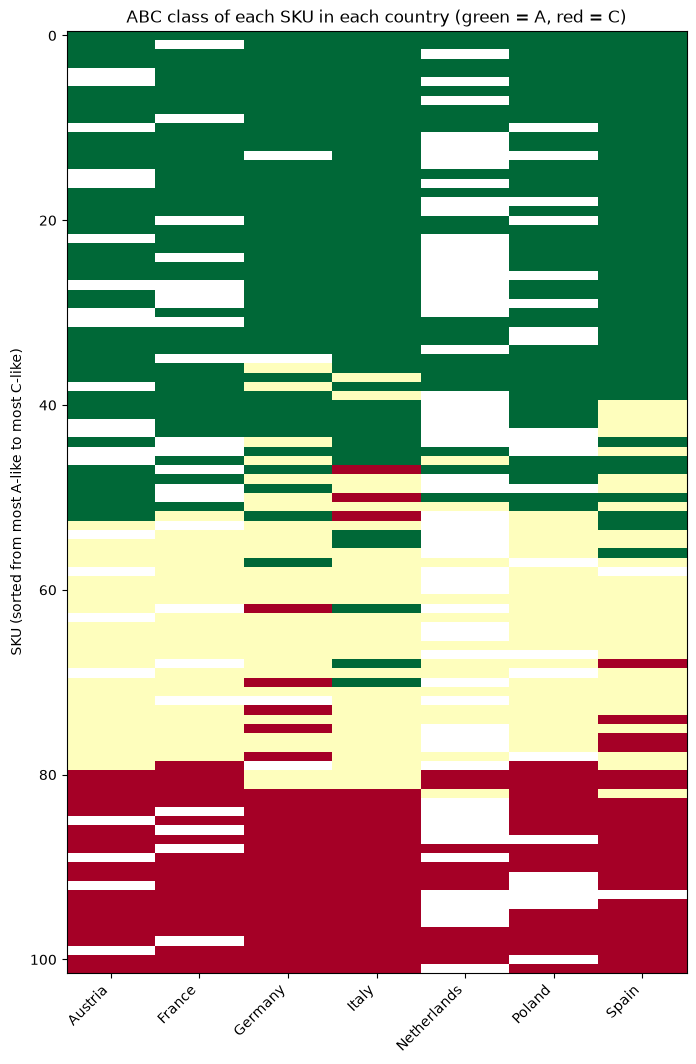

In [13]:
codes = mat.replace({"A": 0, "B": 1, "C": 2}).astype(float)
order = codes.mean(axis=1).sort_values().index        # most "A-like" SKUs on top
fig, ax = plt.subplots(figsize=(8, max(4, len(order) * 0.12)))
im = ax.imshow(codes.loc[order].values, aspect="auto", cmap="RdYlGn_r", vmin=0, vmax=2)
ax.set_xticks(range(codes.shape[1]), codes.columns, rotation=45, ha="right")
ax.set_ylabel("SKU (sorted from most A-like to most C-like)")
ax.set_title("ABC class of each SKU in each country (green = A, red = C)")
savefig("regional_abc")
plt.show()

## 8. Geospatial and logistics analysis
### 8.1 Where is the demand?
Each bubble is a city: size shows net sales and colour shows the variability of lead times (std of days). The second panel is a weighted density map of net sales over the coordinates. Pure matplotlib is used, so no map tiles are drawn; an interactive map is created in 8.2.

Cities: 9 | coordinates unique per city? {'latitude': 2, 'longitude': 2}


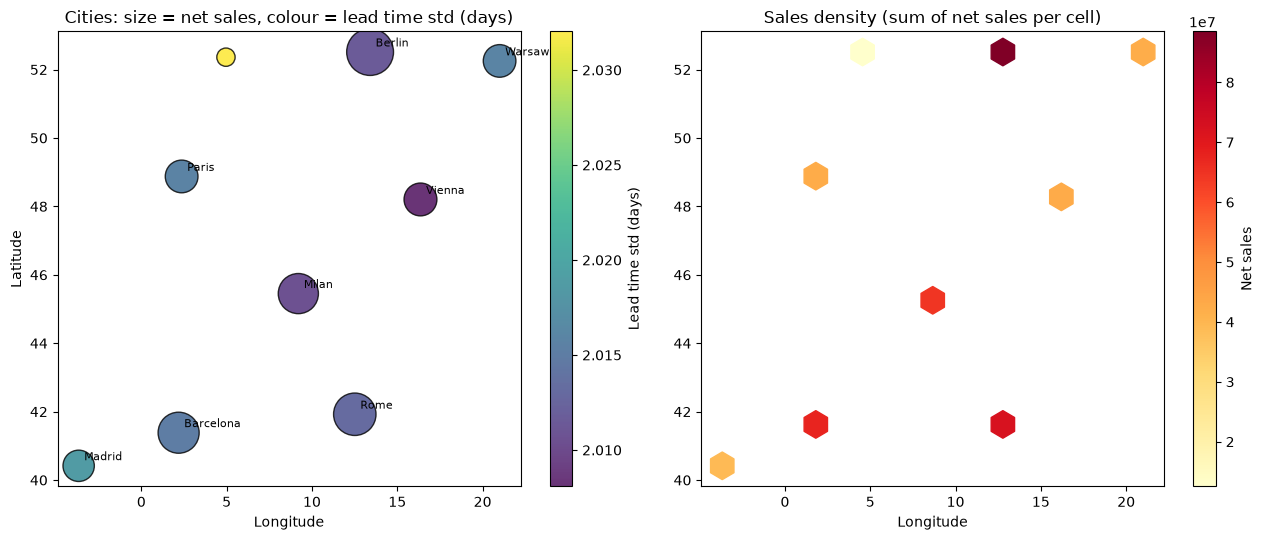

In [14]:
city = (df.groupby(["country", "city"])
          .agg(lat=("latitude", "mean"), lon=("longitude", "mean"),
               stores=("store_id", "nunique"),
               net_sales=("net_sales", "sum"), units=("units_sold", "sum"),
               lt_mean=("lead_time_days", "mean"), lt_std=("lead_time_days", "std"),
               stockout=("stock_out_flag", "mean"))
          .reset_index())
city["sales_share_%"] = city["net_sales"] / city["net_sales"].sum() * 100
print("Cities:", len(city), "| coordinates unique per city?",
      df.groupby("city")[["latitude", "longitude"]].nunique().max().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc = axes[0].scatter(city["lon"], city["lat"], s=city["sales_share_%"] * 60 + 15,
                     c=city["lt_std"], cmap="viridis", alpha=0.8, edgecolor="k")
for _, r in city.nlargest(8, "net_sales").iterrows():
    axes[0].annotate(r["city"], (r["lon"], r["lat"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[0].set_title("Cities: size = net sales, colour = lead time std (days)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(sc, ax=axes[0], label="Lead time std (days)")

hb = axes[1].hexbin(city["lon"], city["lat"], C=city["net_sales"], reduce_C_function=np.sum,
                    gridsize=18, cmap="YlOrRd", mincnt=1)
axes[1].set_title("Sales density (sum of net sales per cell)")
axes[1].set_xlabel("Longitude")
plt.colorbar(hb, ax=axes[1], label="Net sales")
plt.tight_layout()
savefig("sales_map")
plt.show()

### 8.2 Interactive heat map (optional)
Creates `reports/sales_heatmap.html`. Open it in a browser; the map tiles need an internet connection.

In [15]:
try:
    import folium
    from folium.plugins import HeatMap

    m = folium.Map(location=[city["lat"].mean(), city["lon"].mean()], zoom_start=4, tiles="CartoDB positron")
    HeatMap(city[["lat", "lon", "net_sales"]].values.tolist(), radius=35, blur=25).add_to(m)
    for _, r in city.iterrows():
        folium.CircleMarker([r["lat"], r["lon"]], radius=3, color="black", fill=True,
                            tooltip=f"{r['city']}, {r['country']}: {r['sales_share_%']:.1f}% of sales, "
                                    f"lead time std {r['lt_std']:.2f}d").add_to(m)
    m.save("../reports/sales_heatmap.html")
    print("Saved reports/sales_heatmap.html")
except ModuleNotFoundError:
    print("folium is not installed: run %pip install folium, restart the kernel, then rerun this cell.")

Saved reports/sales_heatmap.html


### 8.3 "Logistics deserts" and lead time vs stock-outs
A **logistics desert** is a place where **demand is high** and **lead times are unreliable**, so service failures cost the most. We flag cities in the top quartile for *both* sales and lead-time standard deviation.

Then, as the brief asks, we scatter lead time variability against stock-out rate (by store and by city) and test the link with a Spearman rank correlation. A correlation near 0 means unreliable lead times do not translate into more stock-outs.

Lead time std across cities: min 2.008 | max 2.032
Cities flagged as logistics deserts: 0 of 9
Empty DataFrame
Columns: [country, city, sales_share_%, lt_mean, lt_std, stockout]
Index: []


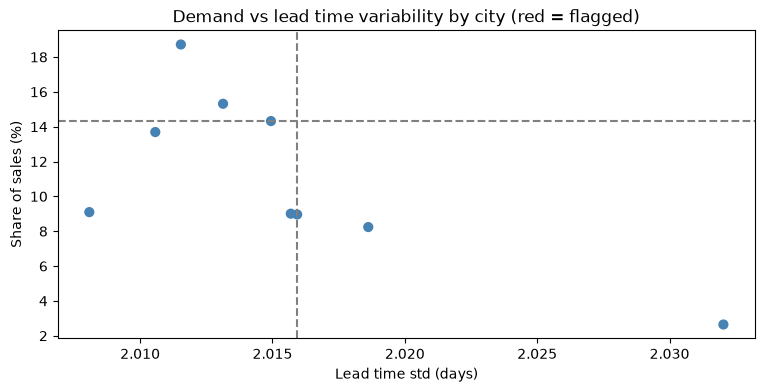

In [16]:
q_sales = city["net_sales"].quantile(0.75)
q_var = city["lt_std"].quantile(0.75)
city["desert"] = (city["net_sales"] >= q_sales) & (city["lt_std"] >= q_var)

print("Lead time std across cities: min", round(city["lt_std"].min(), 3), "| max", round(city["lt_std"].max(), 3))
print("Cities flagged as logistics deserts:", int(city["desert"].sum()), "of", len(city))
print(city[city["desert"]][["country", "city", "sales_share_%", "lt_mean", "lt_std", "stockout"]]
      .sort_values("sales_share_%", ascending=False).round(3).to_string(index=False))
city.to_csv("../reports/city_logistics.csv", index=False)

plt.scatter(city["lt_std"], city["sales_share_%"], c=np.where(city["desert"], "red", "steelblue"), s=40)
plt.axvline(q_var, color="grey", linestyle="--")
plt.axhline(city["sales_share_%"].quantile(0.75), color="grey", linestyle="--")
plt.xlabel("Lead time std (days)")
plt.ylabel("Share of sales (%)")
plt.title("Demand vs lead time variability by city (red = flagged)")
savefig("logistics_deserts")
plt.show()

By store: Spearman rho = 0.110, p-value = 0.721
By city: Spearman rho = -0.067, p-value = 0.865


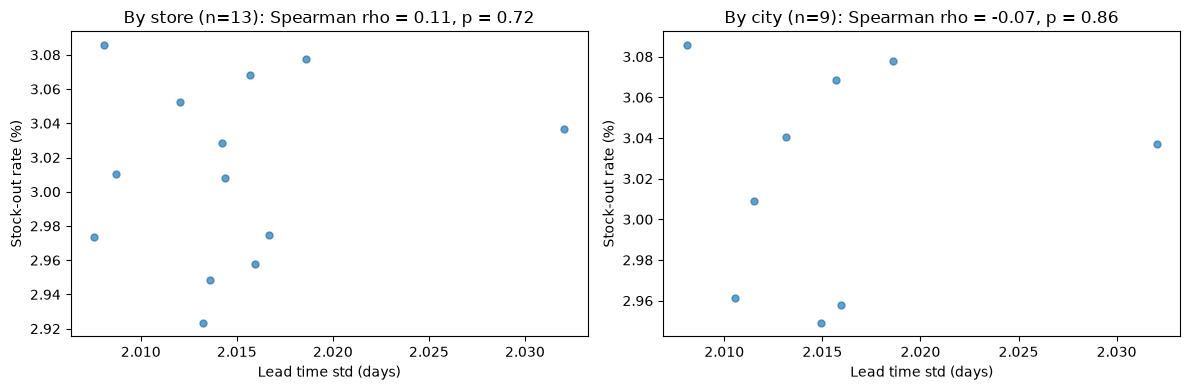

In [17]:
store = (df.groupby(["store_id", "city", "country", "channel"])
           .agg(lt_std=("lead_time_days", "std"), lt_mean=("lead_time_days", "mean"),
                stockout=("stock_out_flag", "mean"))
           .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, d, label in [(axes[0], store, "store"), (axes[1], city, "city")]:
    x, y = d["lt_std"], d["stockout"] * 100
    rho, p = st.spearmanr(x, y)
    ax.scatter(x, y, s=25, alpha=0.7)
    ax.set_xlabel("Lead time std (days)")
    ax.set_ylabel("Stock-out rate (%)")
    ax.set_title(f"By {label} (n={len(d)}): Spearman rho = {rho:.2f}, p = {p:.2f}")
    print(f"By {label}: Spearman rho = {rho:.3f}, p-value = {p:.3f}")
plt.tight_layout()
savefig("leadtime_vs_stockout")
plt.show()

## 9. Summary of findings
*(Fill in after running. Suggested prompts:)*

- **Regional volatility:** Which countries and cities have the highest weekly CV? Is the spread large or small?
- **Correlations:** Pooled vs within-series correlation between units and price/discount/promo. Why do they differ?
- **Price elasticity (A-products):** Net price elasticity and its 95% CI; the discount elasticity; the list-price elasticity (or the note that list price never changes within a series). Does elasticity weaken at deeper discounts (arc elasticity table)?
- **Mann-Whitney U:** p-values, P(promo > non-promo) and rank-biserial r for raw and relative units. Which version is trustworthy and why?
- **Stationarity:** ADF/KPSS result on total demand; share of sampled series that are stationary; whether differencing is needed.
- **Regional ABC:** How many SKUs are A in one country and C in another? Is a single global ABC list adequate?
- **Geospatial and logistics:** Where is demand concentrated? Any logistics deserts? Does lead time variability relate to stock-outs (Spearman rho)?
- **Limitations:** uniform, apparently simulated data; the elasticity is observational; no map tiles in the static plots.